In [1]:
import numpy as np
from itertools import combinations
from validation import _validate_operator, _validate_observable, _validate_stabiliser_set
from dictionaries import pauli_prod_dict, sdict, hdict, cnotdict
from helpers import _stabiliser_group, prepare_gates, prepare_observable, start_trial, compute_elapsed
from time import perf_counter
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

### Introduction

The following codebook is designed to guide one through the building of an efficient classical simulator for n-qubit systems using the stabiliser formalism and Gottesman-Knill theorem. 

### Reprentation of a Quantum State

The following codebook has implemented the following conventions and definitions for various objects. The examples given will correspond to what that object may look like when simulating a 2, 3, 4 qubit system. (except stabiliser set this only has a 3)

`pauli`: A singular character, stored as a string. It must be one of `"I"`, `"X"`, `"Y"`, or `"Z"`.
> e.g. `"X"`, `"Z"`, `"Y"`

`paulistring`: A string of many individual paulis, whose length matches the number of qubits we are simulating. Each pauli represents an operation on the qubit corresponding to its position in the string. 
> e.g. `"XX"`, `"YIY"`, `"XIZY"`

`phase`: A complex integer to represent the phase of a stabiliser or operator. It must be one of `1`, `-1`, `1j`, or `-1j`
> e.g. `1j`, `-1`, `1`

`stabiliser`: A tuple containing one phase and one pauli string. Stabilisers cannot have complex phases. 
> e.g. `(1, "XZ")`, `(-1, "IXX")`, `(1, "ZYXI")`

`stabiliser_set`: A list whose elements are all stabiliser sets. A stabiliser set on n qubits must contain n stabilisers to uniquely identify a set. Further all stabilisers in a set must mutually commute. 
> e.g. `[(1, "XZ"),(-1, "YX")]`

> e.g. `[(-1, "IIX"),(1, "IXI"),(1, "XII")]`

> e.g. `[(1, "IZZI"),(-1, "XIIX"),(-1, "IYYI"),(1, "IIY")]`

These make up the basic building blocks necessary to represent a quantum state. 




Recall that mathematically, a stabiliser set, S, must satisfy three hard conditions:

- All elements must must be Hermitian Pauli observalbles.

- All elements of the set must mutually commute.

- The negative identity may not appear as an element of the stabiliser group. 

We will design the second of these only, as the other conditions require a more advanced representation of the stabiliser formalism. The remaining checks have already been built, and have been imported from `validation.py`.

Below, `_commutation_1qubit` will accept two Paulis and return a parity, corresponding to whether the Paulis commute or anticommute. `_commutation` should then use this, to determine whether two stabilisers commute. 

In [2]:
def _commutation_1qubit(pauli1, pauli2):
    comm_string = pauli1+pauli2
    if "I" in comm_string:
        return 1
    elif pauli1 == pauli2:
        return 1
    else:
        return -1

def _commutation(stab1, stab2):
    parity = 1
    for i in range(len(stab1[1])):
        parity = parity * _commutation_1qubit(stab1[1][i], stab2[1][i])
    return parity

### Operations on Quantum States

`operator`: There are two types of operators, which can either be the tensor product of 1-qubit operations, or a single 2-qubit entangling operation. These are formatted in lists, with the first element being the phase of the operation and the second being a string to represent the operation itself.

>e.g. `[-1j, "XS"]`, `[1, "YHZ"]`, `[-1, "CNOT_IIZX"]`

The string element can take one of two formats:

**1 qubit operators**: The string element must have length equal to the number of qubits, and whose elements are either a pauli, or either of `"H"` and `"S"`.
>e.g. `"HS"`, `"IXY"`, `"ISZH"`

**Entangling operator**: The string element must start with `"CNOT_"`, to signify an entangling gate, and be followed by a string of length corresponding to the number of qubits. This latter string may contain exactly one `"C"` and one `"T"`. These represent the CNOT operation utilising a control and target qubit, corresponding to the positions of `"C"` and one `"T"` respectively. All other elements of this string must be identities, `"I"`. 
>e.g. `"CNOT_CT"`, `"CNOT_CIT"`, `"CNOT_ITIC"`

A crucial operation we need to be able to perform is to determine the product of two stabilisers. A dictionary mapping all products as strings has been provided for you in `dictionaries.py`, and imported as `pauli_prod_dict`. The dictionary is indexed by two paulis concatenated into a single string (e.g. X*Y is indexed as `"XY"`) and will return the phase and resulting pauli as a tuple. 

In [3]:
def _stabiliser_product(stabiliser1, stabiliser2):
    """Calculates the direct matrix product between two stabiliser-type objects."""
    product = ""
    phase = stabiliser1[0]*stabiliser2[0]
    for a, b in zip(stabiliser1[1], stabiliser2[1]):
        factor, pauli = pauli_prod_dict[a + b]
        phase *= factor
        product += pauli
    return phase, product

As we know, another key operation we need to perform is conjugation of our stabilisers by arbitrary cliffords. This allows us to evolve the state by the operator in the stabiliser formalism. 

The helper, `_conj_pauli`, should compute the conjugation of a single Pauli by another Pauli. `_conj_clifford` should then iterate over a the Pauli string component of a stabiliser to find the conjugation by an arbitrary 1-qubit tensored clifford unitary. The dictionaries `hdict` and `sdict` are provided to map a between Paulis under conjugation by respective cliffords. Once again, these will return both phase and a Pauli. 

In [4]:
def _conj_pauli(pauli, op):
    """Takes a pauli gate as a string and conjugates it with another pauli gate. """
    phase = _commutation_1qubit(pauli, op)
    return phase, pauli

def _conj_clifford(stabiliser, operator):
    pauli_string = stabiliser[1]
    new_phase = stabiliser[0]
    new_string = ""
    for i in range(len(pauli_string)):

        if operator[1][i] == "I":
            add_phase, add_string = 1, pauli_string[i]
        elif operator[1][i] in ("X","Y","Z"):
            add_phase, add_string = _conj_pauli(pauli_string[i], operator[1][i])
        elif operator[1][i]=="H":
            add_phase, add_string = hdict[pauli_string[i]]
        elif operator[1][i]=="S":
            add_phase, add_string = sdict[pauli_string[i]]

        new_phase *= add_phase
        new_string += add_string

    return new_phase, new_string

Finally, we need to be be able to conjugate a stabiliser by a 2-qubit entangling gate. Once again, `cnotdict` is provided for the mappings between 2-qubit Pauli strings under CNOT conjugation. 

hint 1: entangling operators have a leading string `"CNOT_"` to sign themselves. Remember that only the end of the operator's string actually contains the operator information. 

In [5]:
def _conj_cnot(stabiliser, cnot_op):
    pauli_phase = stabiliser[0]
    pauli_string = stabiliser[1]
    
    # remove leading CNOT_, find positions of control and target, and identify string "CT"
    cnot_op =  (cnot_op[0], cnot_op[1].removeprefix("CNOT_"))
    control = cnot_op[1].find("C")
    target = cnot_op[1].find("T")
    ct_qubits = pauli_string[control]+pauli_string[target]

    # if there is only one I, take conjugate from dict. 
    phase, ct_qubits = cnotdict[ct_qubits]
    pauli_phase *= phase

    # insert qubits back into string
    pauli_string = pauli_string[:control] + ct_qubits[0] + pauli_string[control+1:]
    pauli_string = pauli_string[:target] + ct_qubits[1] + pauli_string[target+1:]
    return pauli_phase, pauli_string


With these operations, we can now define arbitrary clifford operations on stabiliser sets. We have `transform_stabiliser` which will operate on a stabiliser and evolve it by conjugation .

hint: be careful to track the phase of each stabiliser correctly.


In [6]:
def transform_stabiliser(stabiliser, operator):
    if operator[1].startswith("CNOT_"):
        new_phase, transformed_string = _conj_cnot(stabiliser, operator)
    else: 
        new_phase, transformed_string = _conj_clifford(stabiliser, operator)
    return new_phase, transformed_string

def transform_state(n_qubits, stabiliser_set, operator):
    # validate the operator
    _validate_operator(n_qubits, operator)

    # perform the transformation
    for i,stabiliser in enumerate(stabiliser_set):
        stabiliser_set[i] = transform_stabiliser(stabiliser,operator)
    return stabiliser_set

### Measurement of Quantum States

In the Stabiliser formalism, we are able to measure any Pauli-Observable. Here, the structure of an observable is identical to the structure of a stabiliser. The only difference arises in interpretation. 

`observable`: A tuple containing one phase and one pauli string. Stabilisers cannot have complex phases. 
> e.g. `(1, "XZ")`, `(-1, "IXX")`, `(1, "ZYXI")`

In the following, implement the necessary measurement protocols in the event the observable commutes with all elements of the stabiliser group, just one or many. 

In [ ]:
def _comm_measurement(stabiliser_set, stabiliser_group, observable):
    # A pure stabiliser state is an eigenstate if all generators commute. 
    if observable in stabiliser_group:
        return 1, stabiliser_set
    elif (-observable[0], observable[1]) in stabiliser_group:
        return -1, stabiliser_set
    else:
        raise ValueError("Neither the observable nor its negative is in the stabiliser group.")

def _1_anti_comm_measurement(stabiliser_set, observable, anti_indices):
    outcome = int(np.random.choice([-1, 1]))
    stabiliser_set[anti_indices[0]] = (outcome * observable[0], observable[1])
    return outcome, stabiliser_set

def _many_anti_comm_measurement(stabiliser_set, observable, anti_indices):
    # select one set element to anti-commute, multiply all other anti_commuting elements by that element to get set with one anti_commutation
    anti_index = anti_indices[0]
    anti_stabiliser = stabiliser_set[anti_index]
    for index in anti_indices[1:]:
        stabiliser_set[index] = _stabiliser_product(stabiliser_set[index], anti_stabiliser)
    return _1_anti_comm_measurement(stabiliser_set, observable, [anti_index])


Now, we can bundle these measurement protocols together. 

In [ ]:
def measure_state(stabiliser_set, stabiliser_group, observable):
    _validate_observable(observable)  
    anti_indices = []
    for i,stab in enumerate(stabiliser_set):
        if _commutation(stab,observable) == -1:
            anti_indices.append(i)

    num_anti = len(anti_indices)
    if num_anti == 0:
        return _comm_measurement(stabiliser_set, stabiliser_group, observable)
    elif num_anti == 1:
        return _1_anti_comm_measurement(stabiliser_set, observable, anti_indices)
    else:
        return _many_anti_comm_measurement(stabiliser_set, observable, anti_indices)

### Testing our Simulator

Now, we have defined how we represent quantum states, how we can perform operations on these states and finally how to read out observables and update the resulting state. This is everything we need for a complete simulator for all pure states that can be described by the stabiliser formalism. 

We will now bundle our functions together into a class and demonstrate that these functions indeed scale as O[poly(n)] as desired.

In [8]:
class pure_state:
    def __init__(self):
        self.valid_state = None
        self.n_qubits = None
        self.stabiliser_group = None

    def prepare_identity(self, n_qubits):
        self.n_qubits = n_qubits
        self.valid_state = True
        self.stabiliser_set = [(1, "I" * i + "Z" + "I" * (n_qubits - i - 1)) for i in range(n_qubits)]

    def prepare_state_direct(self, stabiliser_set):
        self.n_qubits = len(stabiliser_set)
        self.valid_state = _validate_stabiliser_set(self.n_qubits, stabiliser_set)
        self.stabiliser_set = stabiliser_set
        self.stabiliser_group = _stabiliser_group(self.stabiliser_set, self.n_qubits)

    def prepare_state_transform(self, stabiliser_set, operator):
        pass

    def get_stabiliser_group(self):
        if self.stabiliser_group is None:
            self.stabiliser_group = _stabiliser_group(self.stabiliser_set, self.n_qubits)
        return self.stabiliser_group

    def transform_state(self, operator):
        self.stabiliser_set = transform_state(self.n_qubits, self.stabiliser_set, operator)
        self.stabiliser_group = None
        try: 
            self.valid_state = _validate_stabiliser_set(self.n_qubits, self.stabiliser_set)
        except ValueError:
            raise ValueError("Transformation produced unexpected state. Could not validate output state.")

    def measure_state(self, observable):
        outcome, self.stabiliser_set = measure_state(self.stabiliser_set,self.get_stabiliser_group(),observable)
        self.stabiliser_group = None
        return outcome


Now, let's test the simulator. Execute the following cell. If everything has gone smoothly, we will simulate the action of 100 randomly instantiated Pauli gates on a bunch of qubits, followed by a random measurement in some basis. We will see that the execution time should grow polynomially with the number of qubits! (allowing for some overhead)

In [9]:
num_trials = 50
num_qubits = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
num_gates = 100

mean_times = []
for i in num_qubits:
    times = []

    for j in range(num_trials):

        state = pure_state()
        state.prepare_identity(i)
        observable = prepare_observable(i)
        gates = prepare_gates(i, num_gates)

        start_time = start_trial()

        for gate in gates:
            state.transform_state(gate)

        state.measure_state(observable)

        elapsed = compute_elapsed(start_time, perf_counter())
        times.append(elapsed)

    mean_times.append(np.mean(times))


        

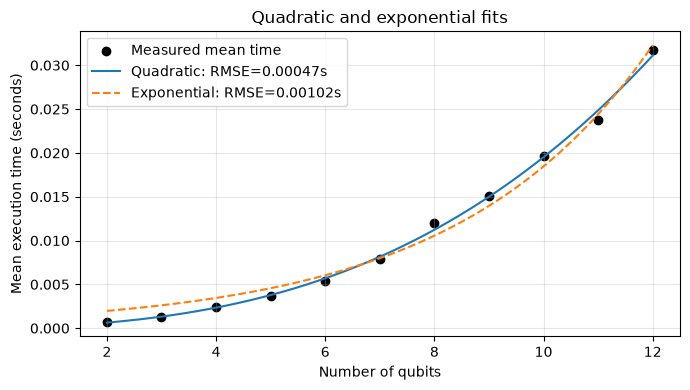

In [ ]:
n = np.array(num_qubits)
times = np.array(mean_times)

# fit polynomial and exponential models
quadratic = np.poly1d(np.polyfit(n, times, deg=3))  # d = 3. transform n generators * check n^2 generator pairs

def exponential(n, a, b):
    return a * np.exp(b * n)
 
b0, log_a0 = np.polyfit(n, np.log(times), deg=1)
params, bin = curve_fit(exponential, n, times,p0=(np.exp(log_a0), b0), maxfev=10000)

quad_rmse = np.sqrt(np.mean((times - quadratic(n))**2))
exp_rmse = np.sqrt(np.mean((times - exponential(n, params[0], params[1]))**2))

n_fit = np.linspace(n.min(), n.max(), 200)

# plot data and fits
plt.figure(figsize=(7, 4))
plt.scatter(n, times, color="black", label="Measured mean time")
plt.plot(n_fit, quadratic(n_fit),label=f"Quadratic: RMSE={quad_rmse:.5f}s")
plt.plot(n_fit, exponential(n_fit, params[0], params[1]), "--", label=f"Exponential: RMSE={exp_rmse:.5f}s")

plt.xlabel("Number of qubits")
plt.ylabel("Mean execution time (seconds)")
plt.title("Quadratic and exponential fits")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Mixed States

Mixed states can likewise be efficiently represented using the stabiliser formalism. Ad hoc, we would simply store many stabiliser sets, alongisde classical probabilities, corresponding to preparation uncertainty. Operations can be performed on all stabiliser sets to update the mixture. Any measurement need only take the outcomes of the individual sets and weigh these by the mixture to return a probabilistic outcome. 
